# Bike Rental Prediction — PRCP-1018

## 1. Project Introduction

### Problem Statement
The objective of this project is to analyze bike-sharing rental data and predict the daily number of bike rentals based on environmental, seasonal, and calendar-related factors.

### Objectives
- Perform exploratory data analysis (EDA).
- Identify factors affecting daily bike rental demand.
- Clean and preprocess the dataset.
- Train and compare multiple regression models.
- Evaluate model performance using MAE, RMSE, and R².
- Document challenges, solutions, and the recommended production model.

### Dataset Description
The dataset contains daily bike rental records, including weather conditions, temperature, humidity, season, holidays, and working-day information.

The target variable is `cnt`, representing the total number of bikes rented per day.

### Tools and Technologies
Python, Jupyter Notebook, Pandas, NumPy, Matplotlib, Seaborn, and Scikit-learn.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv("day.csv")

In [7]:
df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [9]:
df.shape

(731, 16)

In [11]:
df.info

<bound method DataFrame.info of      instant      dteday  season  yr  mnth  holiday  weekday  workingday  \
0          1  2011-01-01       1   0     1        0        6           0   
1          2  2011-01-02       1   0     1        0        0           0   
2          3  2011-01-03       1   0     1        0        1           1   
3          4  2011-01-04       1   0     1        0        2           1   
4          5  2011-01-05       1   0     1        0        3           1   
..       ...         ...     ...  ..   ...      ...      ...         ...   
726      727  2012-12-27       1   1    12        0        4           1   
727      728  2012-12-28       1   1    12        0        5           1   
728      729  2012-12-29       1   1    12        0        6           0   
729      730  2012-12-30       1   1    12        0        0           0   
730      731  2012-12-31       1   1    12        0        1           1   

     weathersit      temp     atemp       hum  windspee

In [13]:
df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [15]:
df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [17]:
df.duplicated().sum()

0

In [19]:
df.groupby("season")["cnt"].mean()

season
1    2604.132597
2    4992.331522
3    5644.303191
4    4728.162921
Name: cnt, dtype: float64

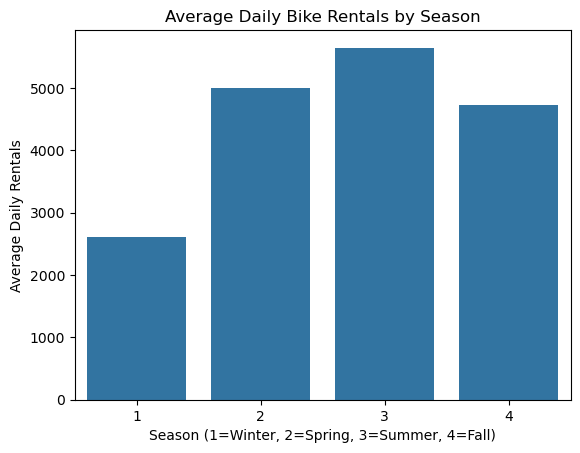

In [21]:
sns.barplot(data=df, x="season", y="cnt", errorbar=None)

plt.title("Average Daily Bike Rentals by Season")
plt.xlabel("Season (1=Winter, 2=Spring, 3=Summer, 4=Fall)")
plt.ylabel("Average Daily Rentals")

plt.show()

In [23]:
df.groupby("weathersit")["cnt"].mean()

weathersit
1    4876.786177
2    4035.862348
3    1803.285714
Name: cnt, dtype: float64

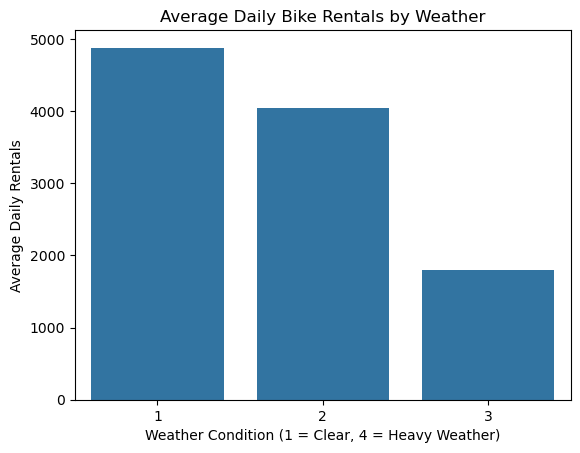

In [25]:
sns.barplot(data=df, x="weathersit", y="cnt", errorbar=None)

plt.title("Average Daily Bike Rentals by Weather")
plt.xlabel("Weather Condition (1 = Clear, 4 = Heavy Weather)")
plt.ylabel("Average Daily Rentals")

plt.show()

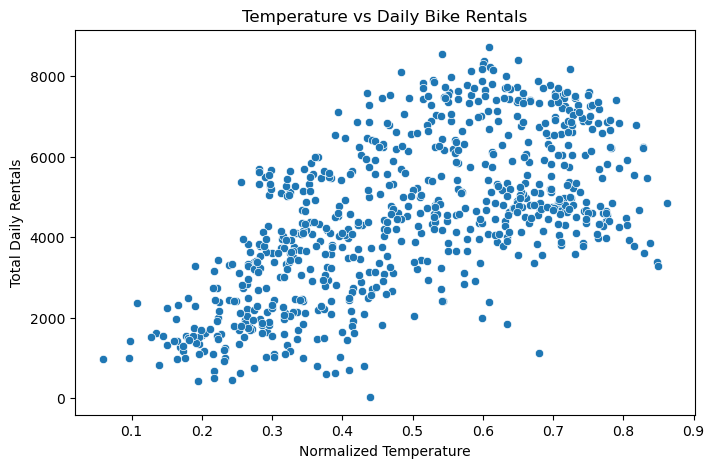

In [27]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="temp", y="cnt")

plt.title("Temperature vs Daily Bike Rentals")
plt.xlabel("Normalized Temperature")
plt.ylabel("Total Daily Rentals")

plt.show()

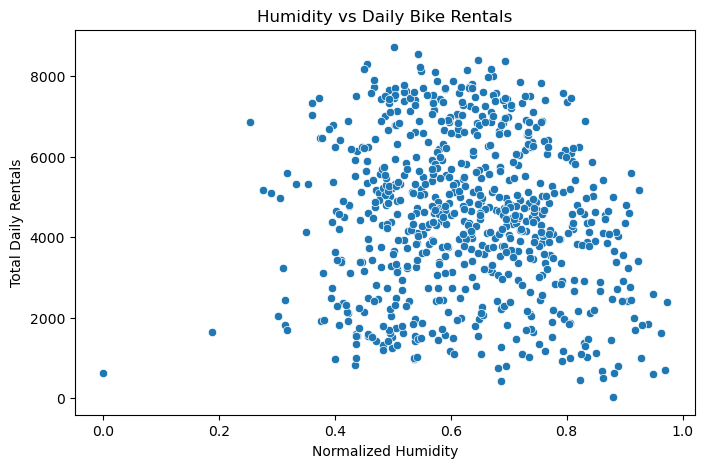

In [29]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="hum", y="cnt")

plt.title("Humidity vs Daily Bike Rentals")
plt.xlabel("Normalized Humidity")
plt.ylabel("Total Daily Rentals")

plt.show()

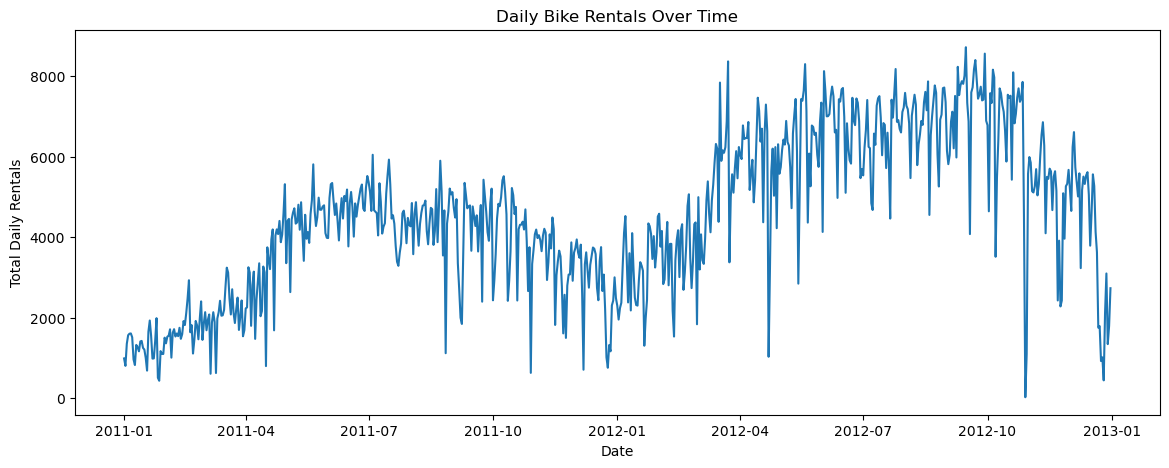

In [31]:
df["dteday"] = pd.to_datetime(df["dteday"])

 
df = df.sort_values("dteday")

 
plt.figure(figsize=(14, 5))

plt.plot(df["dteday"], df["cnt"])

plt.title("Daily Bike Rentals Over Time")
plt.xlabel("Date")
plt.ylabel("Total Daily Rentals")

plt.show()

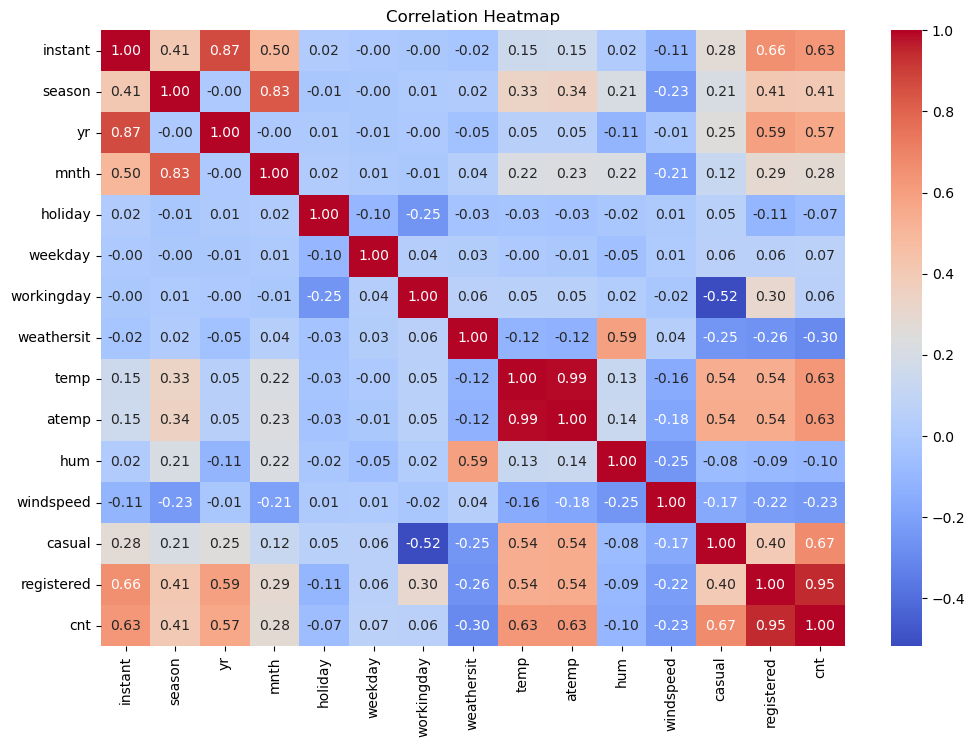

In [33]:
 
numeric_df = df.select_dtypes(include="number")

 
correlation = numeric_df.corr()

 
plt.figure(figsize=(12, 8))

 
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [35]:
print("Minimum rentals:", df["cnt"].min())
print("Maximum rentals:", df["cnt"].max())
print("Average rentals:", round(df["cnt"].mean(), 2))
print("Median rentals:", df["cnt"].median())

Minimum rentals: 22
Maximum rentals: 8714
Average rentals: 4504.35
Median rentals: 4548.0


## 5. Feature Selection

Feature selection identifies the input variables used to predict the target variable. In this project, the target is `cnt`, which represents the total daily bike rental count.

We exclude `casual` and `registered` because their sum equals `cnt`. Using them as inputs would cause data leakage and produce misleading evaluation results.

In [39]:
 
features = [
    "season",
    "yr",
    "mnth",
    "holiday",
    "weekday",
    "workingday",
    "weathersit",
    "temp",
    "atemp",
    "hum",
    "windspeed"
]

 
X = df[features]

 
y = df["cnt"]

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (731, 11)
Target shape: (731,)


In [41]:
 
split_index = int(len(df) * 0.80)

 
X_train = X.iloc[:split_index]
y_train = y.iloc[:split_index]

 
X_test = X.iloc[split_index:]
y_test = y.iloc[split_index:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 584
Testing samples: 147


In [43]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.impute import SimpleImputer

# Categorical input columns
categorical_features = [
    "season", "yr", "mnth", "holiday",
    "weekday", "workingday", "weathersit"
]

# Numerical input columns
numeric_features = ["temp", "atemp", "hum", "windspeed"]

# Preprocess categorical variables
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Preprocess numerical variables
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Apply the appropriate preprocessing to each column
preprocessor = ColumnTransformer(transformers=[
    ("categorical", categorical_transformer, categorical_features),
    ("numeric", numeric_transformer, numeric_features)
])

print("Preprocessing completed.")

Preprocessing completed.


In [45]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        random_state=42, min_samples_leaf=5
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        min_samples_leaf=2,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )
}

# Store trained models and evaluation results
trained_models = {}
results = []

# Train and evaluate each model
for name, model in models.items():

    # Combine preprocessing with the model
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    # Train using the training data
    pipeline.fit(X_train, y_train)

    # Predict rental counts for the test data
    predictions = pipeline.predict(X_test)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    # Save the trained model
    trained_models[name] = pipeline

    # Save the evaluation results
    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

print("All four models trained successfully!")

All four models trained successfully!


In [47]:
 
results_df = pd.DataFrame(results)

# Sort models by RMSE, lowest error first
results_df = results_df.sort_values(
    by="RMSE"
).reset_index(drop=True)

# Display the comparison table
display(results_df.round(2))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,791.67,1093.74,0.66
1,Gradient Boosting,973.56,1139.16,0.63
2,Random Forest,1033.83,1237.84,0.56
3,Decision Tree,1201.10,1436.24,0.41


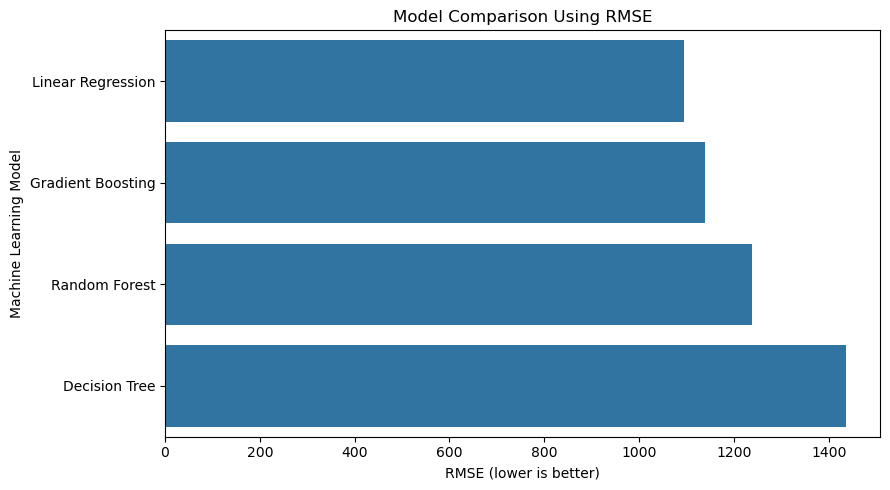

In [49]:
# Compare RMSE values across models
plt.figure(figsize=(9, 5))

sns.barplot(data=results_df, x="RMSE", y="Model")

plt.title("Model Comparison Using RMSE")
plt.xlabel("RMSE (lower is better)")
plt.ylabel("Machine Learning Model")

plt.tight_layout()
plt.show()

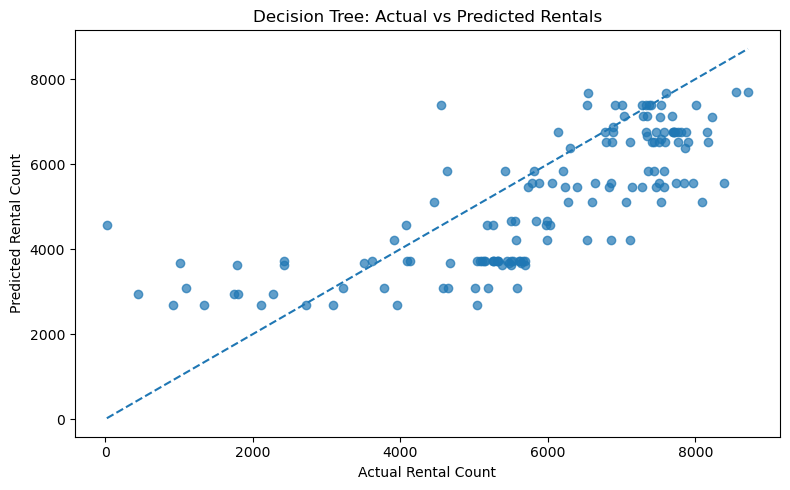

In [51]:
best_model = trained_models["Decision Tree"]

dt_predictions = best_model.predict(X_test)

plt.figure(figsize=(8, 5))
plt.scatter(y_test, dt_predictions, alpha=0.7)

plt.xlabel("Actual Rental Count")
plt.ylabel("Predicted Rental Count")
plt.title("Decision Tree: Actual vs Predicted Rentals")

# Ideal predictions fall on this diagonal
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.tight_layout()
plt.show()

In [53]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Decision Tree Performance")
print("MAE:", round(mean_absolute_error(y_test, dt_predictions), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, dt_predictions)), 2))
print("R2 Score:", round(r2_score(y_test, dt_predictions), 3))

Decision Tree Performance
MAE: 1201.1
RMSE: 1436.24
R2 Score: 0.413


In [55]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

depths = [3, 5, 7, 10, 15, None]
tree_results = []

for depth in depths:
    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", DecisionTreeRegressor(
            max_depth=depth,
            min_samples_leaf=5,
            random_state=42
        ))
    ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    tree_results.append({
        "Max Depth": str(depth),
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    })

tree_results_df = pd.DataFrame(tree_results)
display(tree_results_df.round(2).sort_values("RMSE"))

,Max Depth,MAE,RMSE,R2 Score
0,3,1105.45,1342.06,0.49
1,5,1146.73,1367.11,0.47
2,7,1169.58,1393.39,0.45
4,15,1201.10,1436.24,0.41
5,None,1201.10,1436.24,0.41
3,10,1209.23,1438.23,0.41


In [57]:
best_dt_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DecisionTreeRegressor(
        max_depth=3,
        min_samples_leaf=5,
        random_state=42
    ))
])

best_dt_model.fit(X_train, y_train)

print("Best Decision Tree trained successfully!")

Best Decision Tree trained successfully!


In [59]:
for name, pipeline in trained_models.items():
    predictions = pipeline.predict(X_test)
    print(
        name,
        "| RMSE:",
        round(np.sqrt(mean_squared_error(y_test, predictions)), 2),
        "| R2:",
        round(r2_score(y_test, predictions), 3)
    )

Linear Regression | RMSE: 1093.74 | R2: 0.66
Decision Tree | RMSE: 1436.24 | R2: 0.413
Random Forest | RMSE: 1237.84 | R2: 0.564
Gradient Boosting | RMSE: 1139.16 | R2: 0.631


In [61]:
comparison_models = {
    "Linear Regression": trained_models["Linear Regression"],
    "Tuned Decision Tree": best_dt_model,
    "Gradient Boosting": trained_models["Gradient Boosting"]
}

final_results = []

for name, model in comparison_models.items():
    predictions = model.predict(X_test)

    final_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    })

final_results_df = pd.DataFrame(final_results)
display(final_results_df.round(2).sort_values("RMSE"))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,791.67,1093.74,0.66
2,Gradient Boosting,973.56,1139.16,0.63
1,Tuned Decision Tree,1105.45,1342.06,0.49


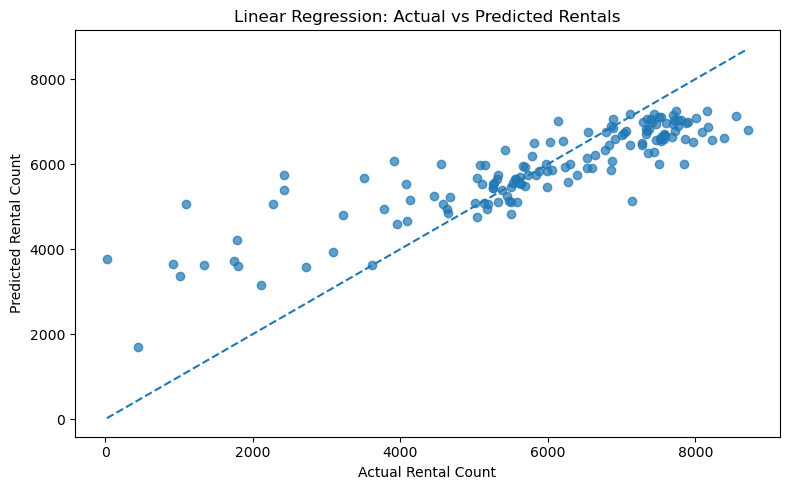

In [63]:
best_model = trained_models["Linear Regression"]
final_predictions = best_model.predict(X_test)

plt.figure(figsize=(8, 5))
plt.scatter(y_test, final_predictions, alpha=0.7)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Rental Count")
plt.ylabel("Predicted Rental Count")
plt.title("Linear Regression: Actual vs Predicted Rentals")
plt.tight_layout()
plt.show()

## Conclusion

The Bike Rental Prediction project uses machine learning to predict daily bike rental demand based on seasonal, weather, and calendar-related features.

The dataset was explored and visualized to understand rental patterns, seasonal variations, weather effects, and relationships between variables. Four regression models were evaluated: Linear Regression, Decision Tree, Random Forest, and Gradient Boosting. The Decision Tree was also tuned by changing its maximum depth.

Among the evaluated models, **Linear Regression achieved the best performance**, with an MAE of 791.67, RMSE of 1093.74, and R² score of 0.66 on the test set.

The results show that machine learning can help estimate bike rental demand. Future improvements could include testing additional features, tuning model parameters, and evaluating performance with time-series-aware validation.
